# Can we predict loan default?

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
loan_df = pd.read_csv("Loan_default.csv")
loan_df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [6]:
loan_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default         25534

In [7]:
loan_df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [8]:
loan_df.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

# Using Somaya's cleaned df 

In [4]:
clean_loan_df = pd.read_csv("Loan_default_cleaned.csv")
clean_loan_df.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DebtToIncomeRatio',
       'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
       'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default',
       'LoanToIncomeRatio'],
      dtype='str')

In [ ]:
# create descriptions for vars to include in data dictionary
# might not include LoanID (?) in data dictionary since it's just a unique identifier
col_descriptions = {
    "LoanID": "Unique identifier for the loan",
    "Age": "Borrower's age in years",
    "Income": "Borrower's annual income",
    "LoanAmount": "Amount of money borrowed ($)",
    "CreditScore": "Borrower's credit score",
    "MonthsEmployed": "Months the borrower has been employed",
    "NumCreditLines": "Number of open credit lines",
    "InterestRate": "Loan interest rate (%)",
    "LoanTerm": "Loan length (in months)",
    "DebtToIncomeRatio": "Debt-to-income ratio",
    "Education": "Highest education level",
    "EmploymentType": "Employment status (full-time, part-time, self-employed, unemployed)",
    "MaritalStatus": "Marital status",
    "HasMortgage": "Whether the borrower has a mortgage (yes/no)",
    "HasDependents": "Whether the borrower has dependents (yes/no)",
    "LoanPurpose": "Reason for loan (home, auto, education, business, other)",
    "HasCoSigner": "Whether the loan has a co-signer (yes/no)",
    "Default": "1 = defaulted on loan, 0 = did not default",
    "LoanToIncomeRatio": "How large the borrower's loan is relative to their income",
}

# create actual data dictionary
data_dictionary = pd.DataFrame({
    "Meaning": clean_loan_df.columns.map(col_descriptions),
    "Data Type": clean_loan_df.dtypes,
    "Unique (#)": clean_loan_df.nunique(),
    "Missing (#)": clean_loan_df.isna().sum(),
}).rename_axis("Column").reset_index() # rename the axis label 

pd.set_option("display.max_colwidth", None) # display all text in meaning column

data_dictionary.style.hide(axis="index") # hides the 0, 1, 2, etc. row numbers

Column,Meaning,Data Type,Unique (#),Missing (#)
Age,Borrower's age in years,int64,52,0
Income,Borrower's annual income,int64,114620,0
LoanAmount,Amount of money borrowed ($),int64,158729,0
CreditScore,Borrower's credit score,int64,550,0
MonthsEmployed,Months the borrower has been employed,int64,120,0
NumCreditLines,Number of open credit lines,int64,4,0
InterestRate,Loan interest rate (%),float64,2301,0
LoanTerm,Loan length (in months),int64,5,0
DebtToIncomeRatio,Debt-to-income ratio,float64,81,0
Education,Highest education level,str,4,0


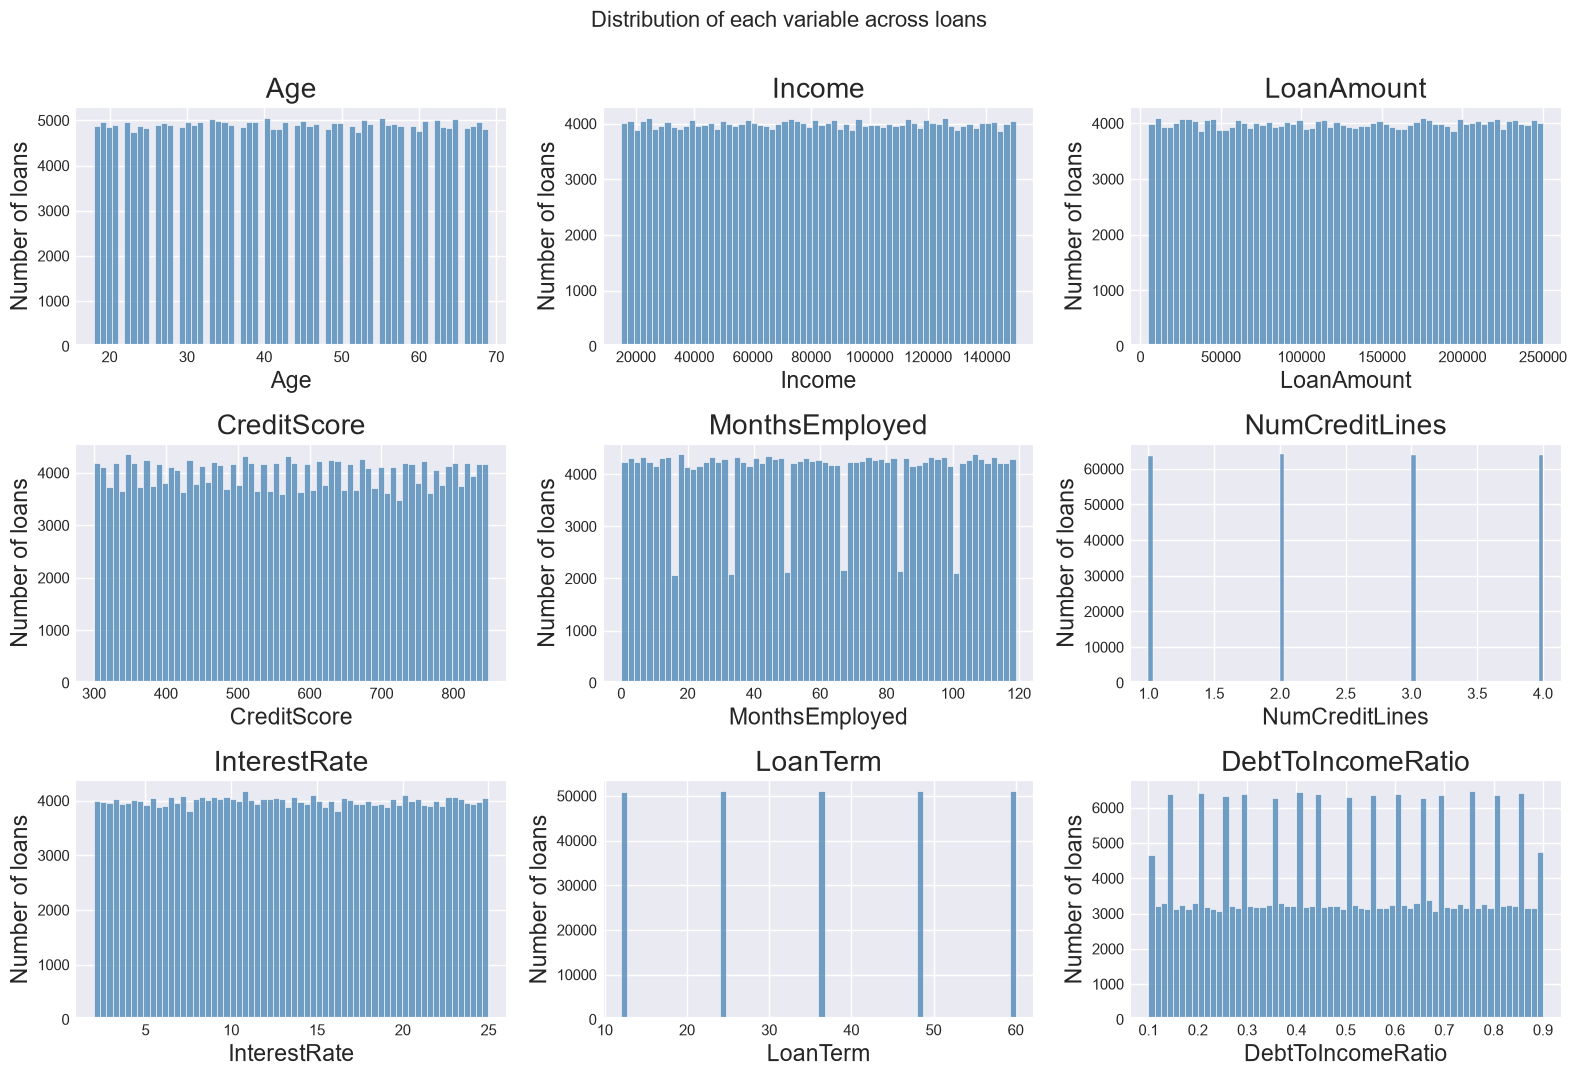

In [109]:
# looking at variable distributions
num_cols = ["Age", "Income", "LoanAmount", "CreditScore", "MonthsEmployed",
            "NumCreditLines", "InterestRate", "LoanTerm", "DebtToIncomeRatio"]

labels = {
    "Age": "Age (years)", "Income": "Annual income", "LoanAmount": "Loan amount",
    "CreditScore": "Credit score", "MonthsEmployed": "Months employed",
    "NumCreditLines": "Number of credit lines", "InterestRate": "Interest rate (%)",
    "LoanTerm": "Loan term (months)", "DebtToIncomeRatio": "Debt-to-income ratio",
}
discrete = {"NumCreditLines", "LoanTerm"}

fig, axes = plt.subplots(3, 3, figsize=(16, 11))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(clean_loan_df[col], ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("Number of loans")

    
fig.suptitle("Distribution of each variable across loans\n", fontsize=16)
plt.tight_layout()
plt.show()

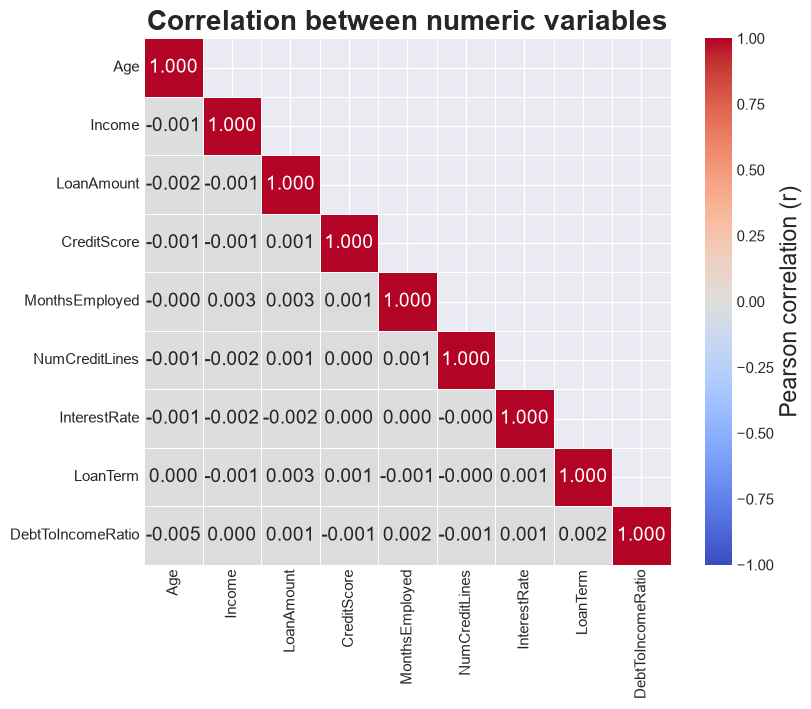

In [112]:
# looking at correlations between numeric variables
corr = clean_loan_df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1) # hide the duplicate upper triangle

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".3f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson correlation (r)"})
plt.title("Correlation between numeric variables", fontweight="bold")
#plt.tight_layout()
plt.show()

C:\Users\corri\AppData\Local\Temp\ipykernel_26840\2728262062.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No default (0)", "Default (1)"])


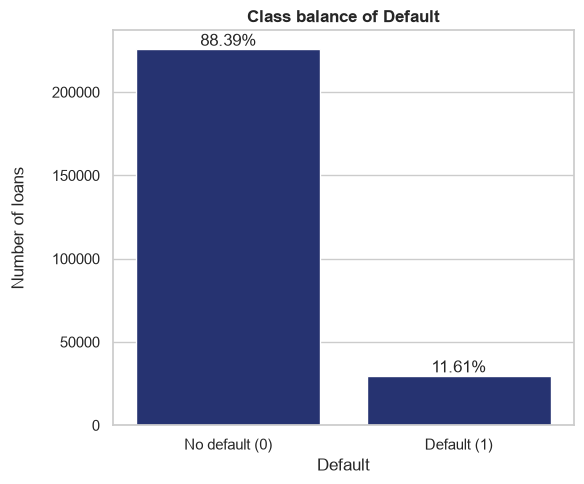

In [ ]:
# look at class counts and percentages
counts = clean_loan_df["Default"].value_counts()
pct = (counts / counts.sum() * 100).round(2)

# trying to make the plot look nicer
sns.set_theme(style="whitegrid")

# bar chart of class imbalance
fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(x="Default", data=clean_loan_df, ax=ax, color="#1a2b7d")
ax.set_xticklabels(["No default (0)", "Default (1)"])
ax.set_ylabel("Number of loans\n")
ax.set_title("Class balance of Default", fontweight="bold")
ax.bar_label(ax.containers[0],labels=[f"{v}%" for v in pct])

plt.tight_layout()
plt.show()

- Clearly there is a fairly large class imbalance here. We should make sure that we use stratified train/test splits and report metrics other than accuracy, as accuracy alone can be misleading when there are class imbalances in the dataset.

- Could we potentially bin age groups, credit scores, employment tenure in years?

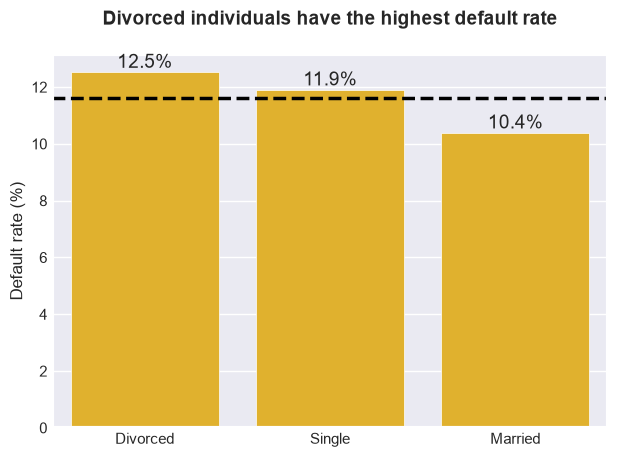

In [ ]:
# messing around with different styles
#plt.style.use("fivethirtyeight")
#sns.set_style("whitegrid")
#sns.set_style("darkgrid")
#sns.set_style("ticks")

# lets create a visual showing how default rates differ for different categorical variables
default_rate_all = clean_loan_df["Default"].mean()*100 # calculate the overall default rate for the dataset as a baseline
marital_status_rates = (clean_loan_df.groupby("MaritalStatus")["Default"].mean()*100).sort_values(ascending=False)

# starting with Marital status
ax = sns.barplot(x=marital_status_rates.index, y=marital_status_rates.values, color="#fdbf11")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.axhline(default_rate_all, color="black", linestyle="--", linewidth=2.5, label=f"Dataset average ({default_rate_all:.1f}%)")

ax.set_title("Divorced individuals have the highest default rate\n", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Default rate (%)", fontsize=12)

plt.tight_layout()
plt.show()

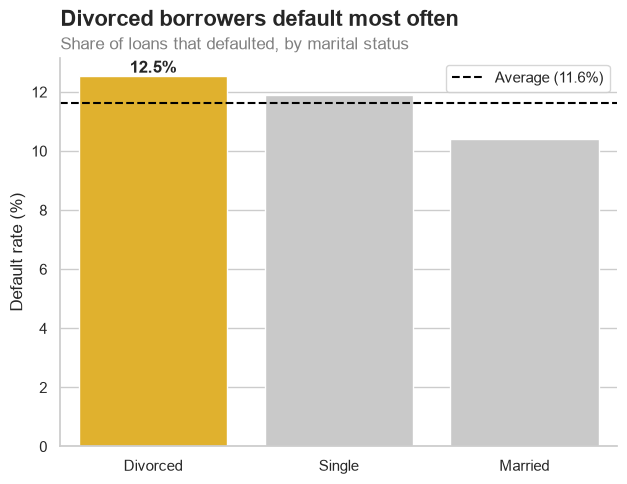

In [ ]:
sns.set_theme(style="whitegrid")

default_rate_all = clean_loan_df["Default"].mean()*100 # calculate average default rate for entire dataset
marriage_rates = (clean_loan_df.groupby("MaritalStatus")["Default"].mean()*100).sort_values(ascending=False)

colors = ["#fdbf11","#c9c9c9","#c9c9c9"] # highlight just the top bar

ax = sns.barplot(x=marriage_rates.index, y=marriage_rates.values, hue=marriage_rates.index, palette=colors, legend=False)
ax.bar_label(ax.containers[0], fmt="%.1f%%", fontweight="bold") # add bold percentage label above bar

ax.axhline(default_rate_all, color="black", linestyle="--", 
           label=f"Average ({default_rate_all:.1f}%)") # add line for average default rate of entire dataset
ax.legend()

# to make subtitle with different properties than title, need to manually adjust the 'x' coordinate for alignment
plt.suptitle("Divorced borrowers default most often", x=0.08, ha="left",fontsize=16, fontweight="bold") # main title
ax.set_title("Share of loans that defaulted, by marital status", #subtitle
             loc="left", fontsize=12, color="gray")

ax.set_xlabel("") # remove x-axis label
ax.set_ylabel("Default rate (%)")

sns.despine() # remove top and right spines for cleaner appearance

plt.show()

Text(0, 0.5, 'Default Rate (%)')

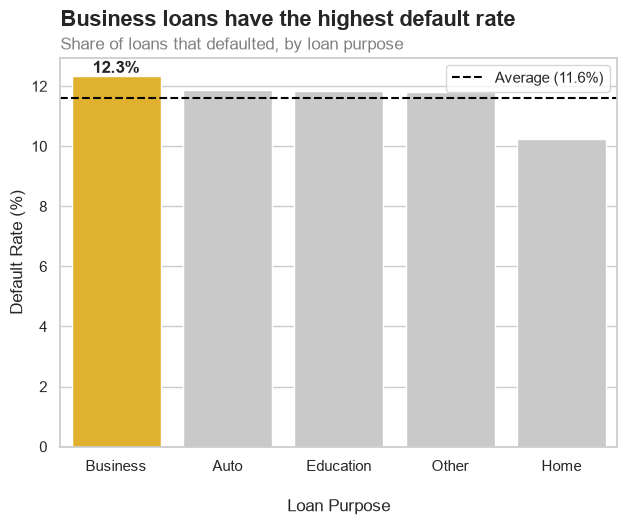

In [160]:
# now lets explore the default rates by loan purpose
loan_purpose_rates = (clean_loan_df.groupby("LoanPurpose")["Default"].mean()*100).sort_values(ascending=False)

colors = ["#fdbf11","#c9c9c9","#c9c9c9","#c9c9c9","#c9c9c9"] # highlight just the top bar

ax = sns.barplot(x=loan_purpose_rates.index, y=loan_purpose_rates.values, hue=loan_purpose_rates.index, palette=colors, legend=False)
ax.bar_label(ax.containers[0], fmt="%.1f%%", fontweight="bold") # add bold percentage label above bar

ax.axhline(default_rate_all, color="black", linestyle="--", 
           label=f"Average ({default_rate_all:.1f}%)") # add line for average default rate of entire dataset
ax.legend()

# to make subtitle with different properties than title, need to manually adjust the 'x' coordinate for alignment
plt.suptitle("Business loans have the highest default rate", x=0.08, ha="left",fontsize=16, fontweight="bold") # main title
ax.set_title("Share of loans that defaulted, by loan purpose", #subtitle
             loc="left", fontsize=12, color="gray")

ax.set_xlabel("\nLoan Purpose")
ax.set_ylabel("Default Rate (%)")